# Experiment 9: Bootstrap Resampling and Uncertainty Estimation

## Import libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(42)
B = 10000

## Load data

In [2]:
tips = sns.load_dataset("tips")
bill = tips["total_bill"].values
n = len(bill)
print("n =", n)
display(tips.head())

print("Sample mean  :", bill.mean().round(4))
print("Sample median:", np.median(bill).round(4))
print("Sample std   :", bill.std(ddof=1).round(4))

n = 244


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


Sample mean  : 19.7859
Sample median: 17.795
Sample std   : 8.9024


## Bootstrap distribution of the mean

Bootstrap samples shape: (10000, 244)
Mean of bootstrap means: 19.7795
Bootstrap standard error: 0.5708
Analytical standard error: 0.5699
Estimated bias: -0.00647


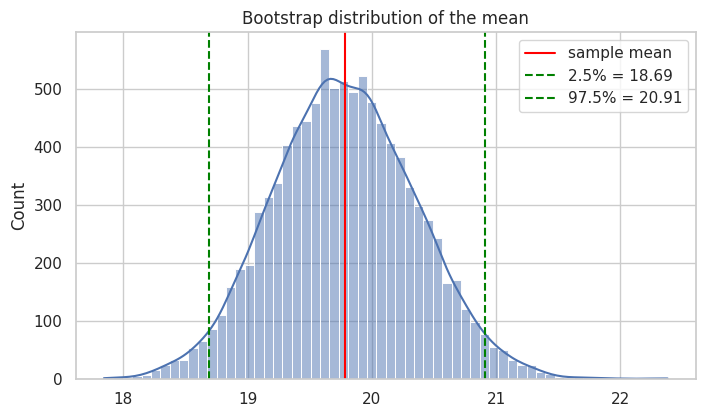

In [3]:
idx = rng.integers(0, n, size=(B, n))
boot_samples = bill[idx]
boot_means = boot_samples.mean(axis=1)
print("Bootstrap samples shape:", boot_samples.shape)
print("Mean of bootstrap means:", boot_means.mean().round(4))

se_boot = boot_means.std(ddof=1)
se_formula = bill.std(ddof=1) / np.sqrt(n)
print("Bootstrap standard error:", se_boot.round(4))
print("Analytical standard error:", se_formula.round(4))
print("Estimated bias:", (boot_means.mean() - bill.mean()).round(5))

lo, hi = np.percentile(boot_means, [2.5, 97.5])
plt.figure(figsize=(8, 4.5))
sns.histplot(boot_means, bins=60, kde=True)
plt.axvline(bill.mean(), color="red", label="sample mean")
plt.axvline(lo, color="green", linestyle="--", label=f"2.5% = {lo:.2f}")
plt.axvline(hi, color="green", linestyle="--", label=f"97.5% = {hi:.2f}")
plt.title("Bootstrap distribution of the mean"); plt.legend()
plt.show()

## Confidence intervals: percentile, basic, normal, BCa and t-interval

In [4]:
est = bill.mean()
percentile_ci = (lo, hi)
basic_ci = (2 * est - hi, 2 * est - lo)
normal_ci = (est - 1.96 * se_boot, est + 1.96 * se_boot)
t_ci = stats.t.interval(0.95, df=n - 1, loc=est, scale=stats.sem(bill))
bca = stats.bootstrap((bill,), np.mean, n_resamples=B, confidence_level=0.95, method="BCa", random_state=42)
pd.DataFrame({
    "lower": [percentile_ci[0], basic_ci[0], normal_ci[0], bca.confidence_interval.low, t_ci[0]],
    "upper": [percentile_ci[1], basic_ci[1], normal_ci[1], bca.confidence_interval.high, t_ci[1]],
}, index=["Percentile", "Basic", "Normal", "BCa (SciPy)", "Classical t"]).round(4)

,lower,upper
Percentile,18.6895,20.9126
Basic,18.6593,20.8824
Normal,18.6671,20.9048
BCa (SciPy),18.7606,20.9477
Classical t,18.6633,20.9086


## Bootstrap for other statistics

,statistic,estimate,boot_SE,boot_bias,CI_lower,CI_upper
0,median,17.7950,0.5331,-0.1036,16.4900,18.6652
1,std,8.9024,0.5046,-0.0425,7.8562,9.8482
2,10% trimmed mean,18.7332,0.5654,0.0122,17.6706,19.8776


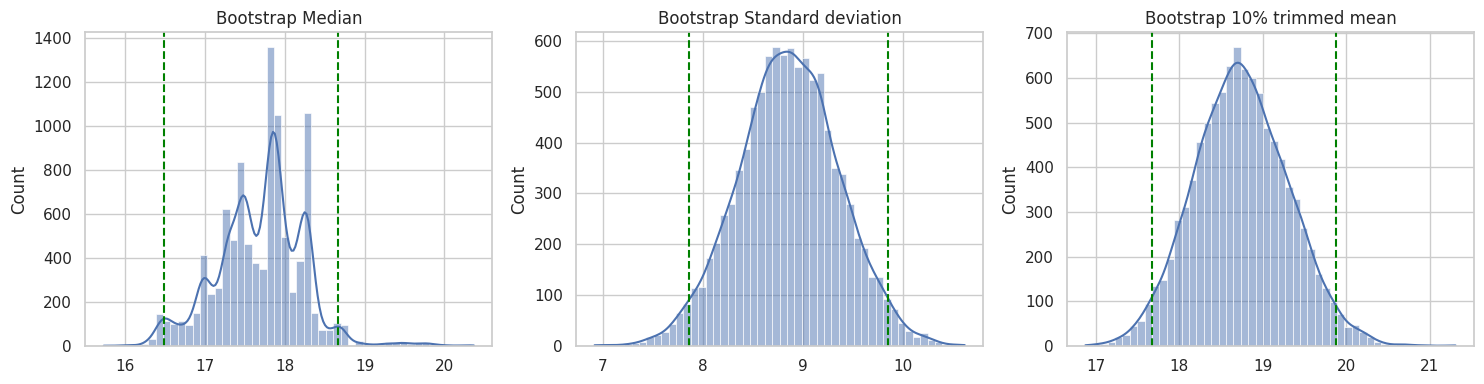

In [5]:
boot_medians = np.median(boot_samples, axis=1)
boot_std = boot_samples.std(axis=1, ddof=1)
boot_trim = stats.trim_mean(boot_samples, 0.1, axis=1)
rows = []
for name, est_, dist in [("median", np.median(bill), boot_medians), ("std", bill.std(ddof=1), boot_std), ("10% trimmed mean", stats.trim_mean(bill, 0.1), boot_trim)]:
    l, h = np.percentile(dist, [2.5, 97.5])
    rows.append([name, est_, dist.std(ddof=1), dist.mean() - est_, l, h])
display(pd.DataFrame(rows, columns=["statistic", "estimate", "boot_SE", "boot_bias", "CI_lower", "CI_upper"]).round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (title, dist) in zip(axes, [("Median", boot_medians), ("Standard deviation", boot_std), ("10% trimmed mean", boot_trim)]):
    sns.histplot(dist, bins=50, kde=True, ax=ax)
    ax.axvline(np.percentile(dist, 2.5), color="green", linestyle="--")
    ax.axvline(np.percentile(dist, 97.5), color="green", linestyle="--")
    ax.set_title(f"Bootstrap {title}")
plt.tight_layout()
plt.show()

## Bootstrap of correlation (pairs resampling)

Observed r = 0.6757, bootstrap SE = 0.0477, 95% CI = (0.5756, 0.7612)


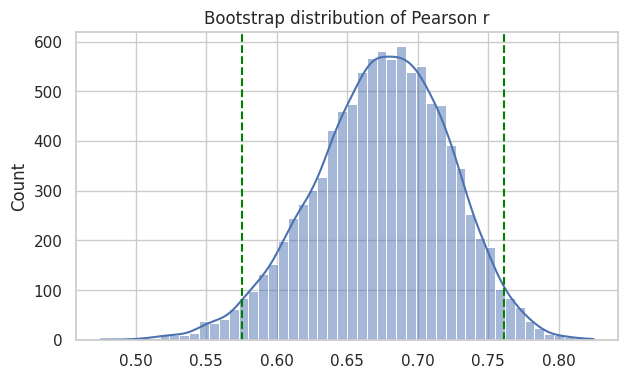

In [6]:
x, y = tips["total_bill"].values, tips["tip"].values
r_obs = np.corrcoef(x, y)[0, 1]
idx = rng.integers(0, n, size=(B, n))
xb, yb = x[idx], y[idx]
r_boot = ((xb - xb.mean(1, keepdims=True)) * (yb - yb.mean(1, keepdims=True))).sum(1) / (
    np.sqrt(((xb - xb.mean(1, keepdims=True)) ** 2).sum(1)) * np.sqrt(((yb - yb.mean(1, keepdims=True)) ** 2).sum(1)))
l, h = np.percentile(r_boot, [2.5, 97.5])
print(f"Observed r = {r_obs:.4f}, bootstrap SE = {r_boot.std(ddof=1):.4f}, 95% CI = ({l:.4f}, {h:.4f})")
plt.figure(figsize=(7, 4))
sns.histplot(r_boot, bins=50, kde=True)
plt.axvline(l, color="green", linestyle="--"); plt.axvline(h, color="green", linestyle="--")
plt.title("Bootstrap distribution of Pearson r")
plt.show()

## Bootstrap of regression coefficients

OLS slope: 0.1050, OLS 95% CI: (0.0905, 0.1195)
Bootstrap slope SE: 0.0117, 95% CI: (0.0827, 0.1280)
Bootstrap intercept 95% CI: (0.5229, 1.3152)


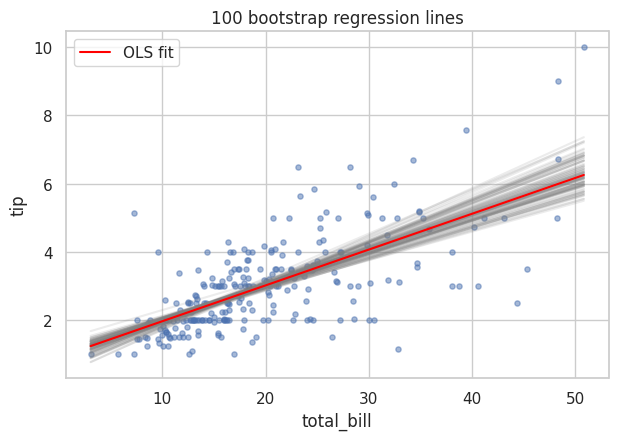

In [7]:
slopes, intercepts = np.empty(B), np.empty(B)
for i in range(B):
    s, c = np.polyfit(x[idx[i]], y[idx[i]], 1)
    slopes[i], intercepts[i] = s, c
ols = sm.OLS(y, sm.add_constant(x)).fit()
print("OLS slope: %.4f, OLS 95%% CI: (%.4f, %.4f)" % (ols.params[1], *ols.conf_int()[1]))
print("Bootstrap slope SE: %.4f, 95%% CI: (%.4f, %.4f)" % (slopes.std(ddof=1), *np.percentile(slopes, [2.5, 97.5])))
print("Bootstrap intercept 95%% CI: (%.4f, %.4f)" % tuple(np.percentile(intercepts, [2.5, 97.5])))

plt.figure(figsize=(7, 4.5))
xs = np.linspace(x.min(), x.max(), 50)
for i in range(100):
    plt.plot(xs, intercepts[i] + slopes[i] * xs, color="gray", alpha=0.15)
plt.scatter(x, y, alpha=0.5, s=14)
plt.plot(xs, ols.params[0] + ols.params[1] * xs, color="red", label="OLS fit")
plt.xlabel("total_bill"); plt.ylabel("tip"); plt.legend(); plt.title("100 bootstrap regression lines")
plt.show()

## Bootstrap hypothesis test for a difference in means

Observed difference: 1.5681
95% bootstrap CI for difference: [-0.7342  3.9708]
Bootstrap p-value: 0.1759
Welch t-test p-value: 0.2008


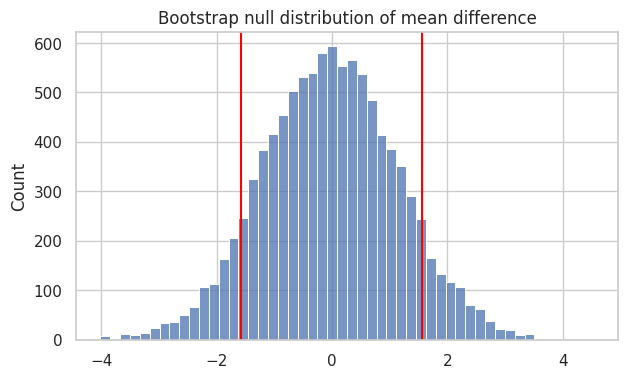

In [8]:
smoker = tips.loc[tips["smoker"] == "Yes", "total_bill"].values
non_smoker = tips.loc[tips["smoker"] == "No", "total_bill"].values
obs_diff = smoker.mean() - non_smoker.mean()
diffs = (rng.choice(smoker, (B, len(smoker))).mean(1) - rng.choice(non_smoker, (B, len(non_smoker))).mean(1))
print("Observed difference:", obs_diff.round(4))
print("95% bootstrap CI for difference:", np.percentile(diffs, [2.5, 97.5]).round(4))

pooled = np.concatenate([smoker, non_smoker])
null = (rng.choice(pooled, (B, len(smoker))).mean(1) - rng.choice(pooled, (B, len(non_smoker))).mean(1))
p_boot = (np.abs(null) >= abs(obs_diff)).mean()
print("Bootstrap p-value:", p_boot)
print("Welch t-test p-value:", stats.ttest_ind(smoker, non_smoker, equal_var=False).pvalue.round(4))
plt.figure(figsize=(7, 4))
sns.histplot(null, bins=50)
plt.axvline(obs_diff, color="red"); plt.axvline(-obs_diff, color="red")
plt.title("Bootstrap null distribution of mean difference")
plt.show()

## Effect of the number of bootstrap resamples

Analytical SE: 0.5699


,B,SE,CI_lower,CI_upper
0,10,0.3252,19.4832,20.4598
1,50,0.4951,18.7579,20.5723
2,100,0.5325,18.9343,20.8949
3,500,0.5376,18.7747,20.8242
4,1000,0.5608,18.6974,20.8691
5,5000,0.5658,18.6905,20.8887
6,10000,0.5708,18.6895,20.9126


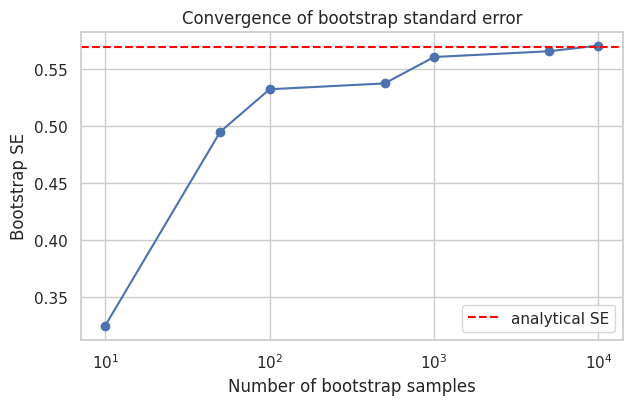

In [9]:
rows = []
for b in [10, 50, 100, 500, 1000, 5000, 10000]:
    m = boot_means[:b]
    rows.append([b, m.std(ddof=1), *np.percentile(m, [2.5, 97.5])])
conv = pd.DataFrame(rows, columns=["B", "SE", "CI_lower", "CI_upper"])
print("Analytical SE:", se_formula.round(4))
display(conv.round(4))

plt.figure(figsize=(7, 4))
plt.semilogx(conv["B"], conv["SE"], marker="o")
plt.axhline(se_formula, color="red", linestyle="--", label="analytical SE")
plt.xlabel("Number of bootstrap samples"); plt.ylabel("Bootstrap SE"); plt.legend()
plt.title("Convergence of bootstrap standard error")
plt.show()

## Bootstrap with a small skewed sample

In [10]:
small = rng.lognormal(mean=1, sigma=0.8, size=15)
small_means = rng.choice(small, (B, len(small))).mean(1)
print("Sample mean:", small.mean().round(4))
print("Bootstrap percentile CI:", np.percentile(small_means, [2.5, 97.5]).round(4))
print("Classical t-interval   :", np.round(stats.t.interval(0.95, df=14, loc=small.mean(), scale=stats.sem(small)), 4))
print("True mean of population:", np.exp(1 + 0.8 ** 2 / 2).round(4))

Sample mean: 4.5756
Bootstrap percentile CI: [3.1656 6.1752]
Classical t-interval   : [2.8828 6.2684]
True mean of population: 3.7434


## Uncertainty of model accuracy

Test accuracy: 0.9883
Bootstrap SE: 0.0083
95% CI for accuracy: [0.9708 1.    ]


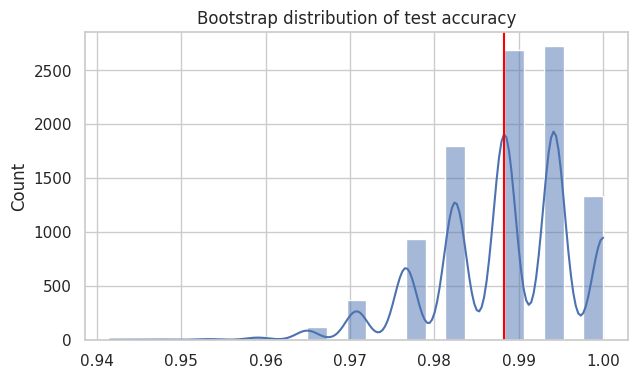

In [11]:
cancer = load_breast_cancer()
Xtr, Xte, ytr, yte = train_test_split(cancer.data, cancer.target, test_size=0.3, random_state=42, stratify=cancer.target)
sc = StandardScaler().fit(Xtr)
model = LogisticRegression(max_iter=5000, random_state=42).fit(sc.transform(Xtr), ytr)
correct = (model.predict(sc.transform(Xte)) == yte).astype(int)
print("Test accuracy:", correct.mean().round(4))
acc_boot = correct[rng.integers(0, len(correct), (B, len(correct)))].mean(1)
print("Bootstrap SE:", acc_boot.std(ddof=1).round(4))
print("95% CI for accuracy:", np.percentile(acc_boot, [2.5, 97.5]).round(4))

plt.figure(figsize=(7, 4))
sns.histplot(acc_boot, bins=25, kde=True)
plt.axvline(correct.mean(), color="red")
plt.title("Bootstrap distribution of test accuracy")
plt.show()

## Out-of-bag evaluation using bootstrap resampling

In [12]:
n_tr = len(ytr)
oob_scores = []
for _ in range(200):
    train_idx = rng.integers(0, n_tr, n_tr)
    oob_idx = np.setdiff1d(np.arange(n_tr), train_idx)
    s = StandardScaler().fit(Xtr[train_idx])
    m = LogisticRegression(max_iter=5000).fit(s.transform(Xtr[train_idx]), ytr[train_idx])
    oob_scores.append(m.score(s.transform(Xtr[oob_idx]), ytr[oob_idx]))
oob_scores = np.array(oob_scores)
print("Mean OOB accuracy:", oob_scores.mean().round(4))
print("95% interval:", np.percentile(oob_scores, [2.5, 97.5]).round(4))

Mean OOB accuracy: 0.9714
95% interval: [0.9434 0.9929]
